<p align="center">
<a href="https://colab.research.google.com/github/md-ryhan-uddin/ai-lab-experiments/blob/main/experiment_08.ipynb">
    <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

<a href="https://kaggle.com/kernels/welcome?src=https://github.com/md-ryhan-uddin/ai-lab-experiments/blob/main/experiment_08.ipynb">
    <img src="https://kaggle.com/static/images/open-in-kaggle.svg" alt="Open In Kaggle" height="20"/>
</a>
</p>

## **Experiment 08:** Image Classification using Convolutional Neural Networks (CNNs) and Transfer Learning

**Course:** ICE 4111: Artificial Intelligence Lab  
**Program:** Bachelor of Science in Information and Communication Engineering (BSc in ICE)  
**Instructor:** Md. Ryhan Uddin

**Student Name:** ______________________________  
**Student ID:** ______________________________  
**Section/Batch:** ______________________________  
**Date of Submission:** ______________________________  


### **Quick Overview**

In this lab, a custom **CNN** with Tanh activation, different convolution filter counts, and Dropout regularization is trained on the Scikit-learn Digits dataset. The same task is then performed with **transfer learning using a frozen EfficientNetB0** pretrained on ImageNet. Both models are evaluated on the same held-out test set using accuracy, classification reports, learning curves, and a confusion matrix.


### **Learning Objectives**

After completing this experiment, students will be able to:

- Design a custom CNN with modified filter counts, kernel sizes, and activation functions.
- Apply Dropout and early stopping to help control overfitting.
- Apply transfer learning using a pretrained EfficientNetB0 feature extractor.
- Prepare grayscale image data for both a custom CNN and a pretrained model.
- Compare models using test accuracy, classification reports, learning curves, and a confusion matrix.


## **Theory**

### Introduction

Convolutional Neural Networks (CNNs) are effective for image classification because convolutional filters learn local patterns such as edges, curves, and shapes. The number of filters controls how many feature patterns a layer can learn, while kernel size determines the local image region examined by each filter. Pooling reduces feature-map dimensions and computation. Activation functions introduce non-linearity: **Tanh** is used in the custom CNN, while **Swish** is used in the transfer-learning classifier head. Dropout randomly disables some activations during training to help reduce overfitting.

**Transfer learning** reuses features learned by a model pretrained on a large dataset. Here, EfficientNetB0 pretrained on ImageNet is used as a frozen feature extractor, and a new classifier head is trained for the ten digit classes. The output layer uses **Softmax**, which converts the ten output scores into class probabilities.

### Model design changes

- **Custom CNN:** 16 filters with a 5×5 kernel, followed by 32 and 64 filters with 3×3 kernels; Tanh activations; Dropout regularization; and a 10-unit Softmax output.
- **Transfer learning:** frozen EfficientNetB0 with 128×128 RGB inputs; Global Average Pooling; a 128-unit Tanh dense layer; Dropout; and a 10-unit Softmax output.
- **Optimization:** RMSprop is used for the custom CNN, while Adam with a smaller learning rate is used to train the transfer-learning classifier head.


### Mathematical Background

For an input image $X$ and kernel $K$ of size $k \times k$, a convolutional feature map is computed by sliding the kernel across the image and taking dot products with local patches:

$$S(i, j) = \sum_{m}\sum_{n} X(i+m,\, j+n)\, K(m, n)$$

followed by a non-linear activation such as ReLU. Pooling (e.g. max pooling) reduces spatial resolution while preserving the most important activations, which controls parameter count and adds a degree of translation invariance.

In transfer learning, a pretrained base model learns a general-purpose feature function $\phi(X)$ on a large source dataset. The base is frozen (its weights are not updated), and only a new classifier head — typically global average pooling followed by one or more dense layers — is trained on the target dataset:

$$\hat{y} = \text{softmax}\big(W_2\, \phi(X) + b_2\big)$$

### Important Concepts

A CNN training pipeline is: prepare images, normalize pixel values, build convolution and pooling blocks, train with early stopping, and evaluate on held-out data. For transfer learning, the same images are resized to match the pretrained model's expected input size, converted to three channels if necessary, and passed through a **frozen** feature extractor so its ImageNet-learned filters are preserved. Only the newly added classifier head is trained. This two-stage idea can be extended with **fine-tuning**, where a few of the base model's top layers are later unfrozen and trained at a very low learning rate to adapt the pretrained features more closely to the target domain.

### Advantages and Applications

**Advantages**
- CNNs learn spatial features using shared convolutional filters.
- Changing filter counts and kernel sizes lets the network learn patterns at different levels.
- Dropout can reduce overfitting, while transfer learning reuses features learned from a large dataset.

**Limitations**
- A model can still overfit when the training dataset is small.
- ImageNet features were learned from natural photographs, so they may not be ideal for tiny 8×8 handwritten digit images.
- Transfer learning requires internet access the first time pretrained weights are downloaded.

**Applications:** handwritten character recognition, medical image analysis, object recognition, remote sensing, and industrial inspection.

```mermaid
flowchart LR
    A[8x8 Grayscale Input] --> B[Conv 16, 5x5 + Tanh]
    B --> C[Pooling]
    C --> D[Conv 32 and 64, 3x3 + Tanh]
    D --> E[Flatten + Dropout]
    E --> F[Dense + Softmax]
    G[EfficientNetB0 Pretrained Base] --> H[Global Average Pooling]
    H --> I[Dense 128 + Tanh + Dropout]
    I --> J[Softmax Output]
```


## **Required Software and Libraries**

- Python 3.10 or later
- Jupyter Notebook, JupyterLab, VS Code, or Google Colab
- NumPy, Pandas, Matplotlib
- TensorFlow 2.x / Keras
- Scikit-learn
- An active internet connection for the first download of pretrained EfficientNetB0 ImageNet weights

### Starter Check

Run the first code cell (library imports and setup). If it prints `Setup complete. You can start the experiment.`, your environment is ready.


## **Dataset Description**

This experiment uses the **Digits dataset** from Scikit-learn.

- **Features:** 8×8 grayscale images of handwritten digits.
- **Target labels:** digits 0 through 9 (10 classes).
- **Source:** `sklearn.datasets.load_digits`.
- **Preprocessing:** pixel values are normalized for the custom CNN. For EfficientNetB0, images are converted to three channels, resized to 128×128, and scaled to the 0–255 range expected by the model's built-in preprocessing.
- **Reason for selection:** the dataset is small, locally available, and suitable for comparing a custom CNN with a pretrained feature extractor.


## **Experimental Procedure**

1. Load the Digits dataset and normalize its pixel values.
2. Split the dataset into training, validation, and test subsets using stratification.
3. Build a custom CNN using Tanh activations, 16/32/64 convolution filters, 5×5 and 3×3 kernels, and Dropout.
4. Train the custom CNN using RMSprop and early stopping.
5. Convert the images to RGB, resize them to 128×128, and prepare them for EfficientNetB0.
6. Load a pretrained EfficientNetB0 base, freeze its weights, and train a new classifier head using Adam.
7. Compare both models using test accuracy, classification reports, learning curves, and a confusion matrix.
8. Inspect correctly classified and misclassified examples.


## **Source Code**

Run the cells in order. The custom CNN and transfer-learning architecture have been modified: the convolution filter counts and kernel sizes are different, Tanh activations are used in the custom CNN and transfer-learning classifier head, Dropout is added, and the pretrained base is changed from MobileNetV2 to EfficientNetB0.

**Note:** The first transfer-learning run downloads EfficientNetB0 ImageNet weights and therefore requires an internet connection.


In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # suppress verbose TensorFlow startup logs

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)
np.random.seed(42)
plt.style.use("seaborn-v0_8-whitegrid")
%matplotlib inline

print("Setup complete. You can start the experiment.")

Setup complete. You can start the experiment.


In [2]:
# Load and Normalize the Digits Dataset

digits = load_digits()
X = digits.images.astype("float32") / 16.0
y = digits.target

print("Shape:", X.shape)
print("Class counts:\n", np.bincount(y))
print("Pixel value range after scaling: [{:.2f}, {:.2f}]".format(X.min(), X.max()))

Shape: (1797, 8, 8)
Class counts:
 [178 182 177 183 181 182 181 179 174 180]
Pixel value range after scaling: [0.00, 1.00]


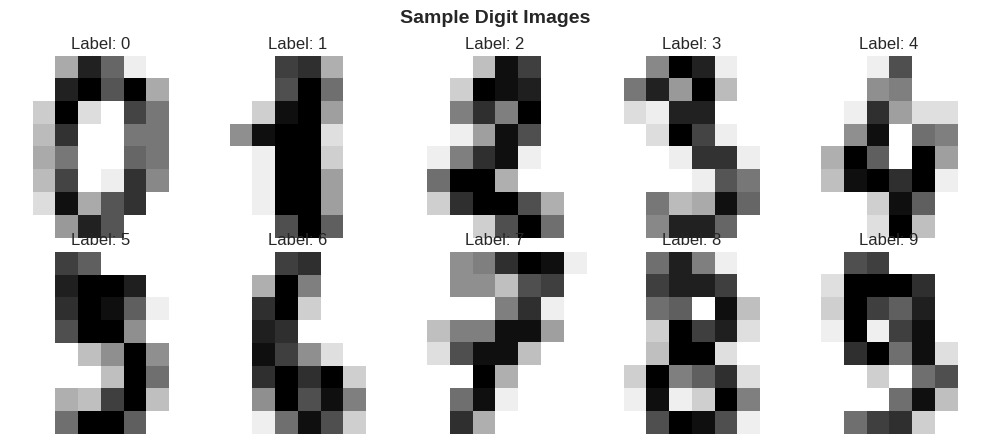

In [3]:
# Visualize Sample Digit Images

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))

for i, ax in enumerate(axes.ravel()):
    ax.imshow(X[i], cmap="gray_r")
    ax.set_title(f"Label: {y[i]}")
    ax.axis("off")

plt.suptitle("Sample Digit Images", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [4]:
# Train / Validation / Test Split

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full,
    test_size=0.2,
    random_state=42,
    stratify=y_train_full,
)

# Add the channel dimension required by Conv2D: (samples, height, width, channels)
X_train_cnn = X_train[..., np.newaxis]
X_val_cnn = X_val[..., np.newaxis]
X_test_cnn = X_test[..., np.newaxis]

print("Train shape     :", X_train_cnn.shape)
print("Validation shape:", X_val_cnn.shape)
print("Test shape      :", X_test_cnn.shape)

Train shape     : (1149, 8, 8, 1)
Validation shape: (288, 8, 8, 1)
Test shape      : (360, 8, 8, 1)


In [5]:
# Build the Modified CNN: Tanh, Changed Filter Counts/Kernel Sizes, and Dropout

cnn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(8, 8, 1)),
    tf.keras.layers.Conv2D(16, (5, 5), activation="tanh", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="tanh", padding="same"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="tanh", padding="same"),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="tanh"),
    tf.keras.layers.Dropout(0.35),
    tf.keras.layers.Dense(10, activation="softmax"),
])

cnn_model.compile(
    optimizer=tf.keras.optimizers.RMSprop(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

cnn_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 8, 8, 16)       │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 4, 4, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 4, 4, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 2, 2, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 2, 2, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,738 (225.54 KB)

 Trainable params: 57,738 (225.54 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Train the CNN with Early Stopping

cnn_history = cnn_model.fit(
    X_train_cnn, y_train,
    validation_data=(X_val_cnn, y_val),
    epochs=40,
    batch_size=24,
    verbose=1,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=6, restore_best_weights=True
    )],
)

print(f"CNN training completed after {len(cnn_history.history['loss'])} epochs.")


Epoch 1/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.3908 - loss: 2.0646 - val_accuracy: 0.7535 - val_loss: 1.6056
Epoch 2/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7258 - loss: 1.1976 - val_accuracy: 0.8785 - val_loss: 0.7784
Epoch 3/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8607 - loss: 0.6526 - val_accuracy: 0.8958 - val_loss: 0.4369
Epoch 4/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9017 - loss: 0.4052 - val_accuracy: 0.9306 - val_loss: 0.2853
Epoch 5/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9304 - loss: 0.2733 - val_accuracy: 0.9444 - val_loss: 0.2135
Epoch 6/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9460 - loss: 0.2033 - val_accuracy: 0.9618 - val_loss: 0.1564
Epoch 7/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9608 - loss: 0.1543 - val_accuracy: 0.9688 - val_loss: 0.1307
Epoch 8/40
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9704 - loss: 0.1238 - val_accuracy: 0.9688 - val_loss

In [7]:
# Evaluate the CNN on the Test Set

cnn_test_prob = cnn_model.predict(X_test_cnn, verbose=0)
cnn_test_pred = np.argmax(cnn_test_prob, axis=1)

cnn_accuracy = accuracy_score(y_test, cnn_test_pred)
print(f"CNN Test Accuracy : {cnn_accuracy:.4f}")
print(classification_report(y_test, cnn_test_pred, target_names=[str(i) for i in range(10)]))

CNN Test Accuracy : 0.9833
              precision    recall  f1-score   support

           0       1.00      0.97      0.99        36
           1       0.92      0.97      0.95        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       0.97      1.00      0.99        36
           5       1.00      1.00      1.00        37
           6       0.97      1.00      0.99        36
           7       0.97      1.00      0.99        36
           8       1.00      0.89      0.94        35
           9       1.00      1.00      1.00        36

    accuracy                           0.98       360
   macro avg       0.98      0.98      0.98       360
weighted avg       0.98      0.98      0.98       360



In [8]:
# Prepare Images for EfficientNetB0 Transfer Learning (RGB, 128x128)

def resize_for_transfer(images):
    images_rgb = np.repeat(images[..., np.newaxis], 3, axis=-1)
    images_resized = tf.image.resize(images_rgb, (128, 128)).numpy()
    # EfficientNetB0 includes its own rescaling/preprocessing layer, so provide pixels in 0-255 range.
    return (images_resized * 255.0).astype("float32")

X_train_tl = resize_for_transfer(X_train)
X_val_tl = resize_for_transfer(X_val)
X_test_tl = resize_for_transfer(X_test)

print("Transfer learning input shape:", X_train_tl.shape)
print("Transfer learning pixel range:", float(X_train_tl.min()), "to", float(X_train_tl.max()))


Transfer learning input shape: (1149, 128, 128, 3)
Transfer learning pixel range: 0.0 to 255.0


In [9]:
# Build Transfer Learning Model: Frozen EfficientNetB0 + Tanh Classifier Head

base_model = tf.keras.applications.EfficientNetB0(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False  # freeze pretrained feature extractor

transfer_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),
    base_model,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(128, activation="tanh"),
    tf.keras.layers.Dropout(0.40),
    tf.keras.layers.Dense(10, activation="softmax"),
])

transfer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

transfer_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,214,829 (16.08 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [10]:
# Train Only the New Classifier Head with Early Stopping

transfer_history = transfer_model.fit(
    X_train_tl, y_train,
    validation_data=(X_val_tl, y_val),
    epochs=15,
    batch_size=24,
    verbose=1,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=4, restore_best_weights=True
    )],
)

print(f"EfficientNetB0 transfer-learning training completed after {len(transfer_history.history['loss'])} epochs.")


Epoch 1/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 43s 676ms/step - accuracy: 0.4778 - loss: 1.6443 - val_accuracy: 0.7743 - val_loss: 0.9840
Epoch 2/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 25s 523ms/step - accuracy: 0.7511 - loss: 0.9402 - val_accuracy: 0.8333 - val_loss: 0.6791
Epoch 3/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 41s 526ms/step - accuracy: 0.8225 - loss: 0.6877 - val_accuracy: 0.8715 - val_loss: 0.5365
Epoch 4/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 25s 516ms/step - accuracy: 0.8494 - loss: 0.5793 - val_accuracy: 0.8889 - val_loss: 0.4520
Epoch 5/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 41s 526ms/step - accuracy: 0.8651 - loss: 0.4903 - val_accuracy: 0.8889 - val_loss: 0.4073
Epoch 6/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 41s 524ms/step - accuracy: 0.8921 - loss: 0.4205 - val_accuracy: 0.8924 - val_loss: 0.3796
Epoch 7/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 41s 517ms/step - accuracy: 0.9086 - loss: 0.3856 - val_accuracy: 0.9028 - val_loss: 0.3538
Epoch 8/15
48/48 ━━━━━━━━━━━━━━━━━━━━ 26s 539ms/step - accuracy: 0.8973 - loss: 0.3765 - val_accu

In [11]:
# Evaluate the Transfer Learning Model on the Test Set

transfer_test_prob = transfer_model.predict(X_test_tl, verbose=0)
transfer_test_pred = np.argmax(transfer_test_prob, axis=1)

transfer_accuracy = accuracy_score(y_test, transfer_test_pred)
print(f"Transfer Learning Test Accuracy : {transfer_accuracy:.4f}")
print(classification_report(y_test, transfer_test_pred, target_names=[str(i) for i in range(10)]))

Transfer Learning Test Accuracy : 0.9361
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.95      0.97      0.96        36
           2       0.85      0.97      0.91        35
           3       0.96      0.73      0.83        37
           4       0.97      1.00      0.99        36
           5       0.88      1.00      0.94        37
           6       0.95      0.97      0.96        36
           7       0.95      0.97      0.96        36
           8       1.00      0.86      0.92        35
           9       0.89      0.89      0.89        36

    accuracy                           0.94       360
   macro avg       0.94      0.94      0.93       360
weighted avg       0.94      0.94      0.93       360



In [12]:
# Compare Custom CNN vs EfficientNetB0 Transfer Learning

comparison_df = pd.DataFrame([
    ["Modified CNN (Tanh + Dropout)", cnn_accuracy, len(cnn_history.history["loss"])],
    ["EfficientNetB0 Transfer Learning", transfer_accuracy, len(transfer_history.history["loss"])],
], columns=["Model", "Test Accuracy", "Epochs Trained"]).round(4)

comparison_df


,Model,Test Accuracy,Epochs Trained
0,Modified CNN (Tanh + Dropout),0.9833,40
1,EfficientNetB0 Transfer Learning,0.9361,15


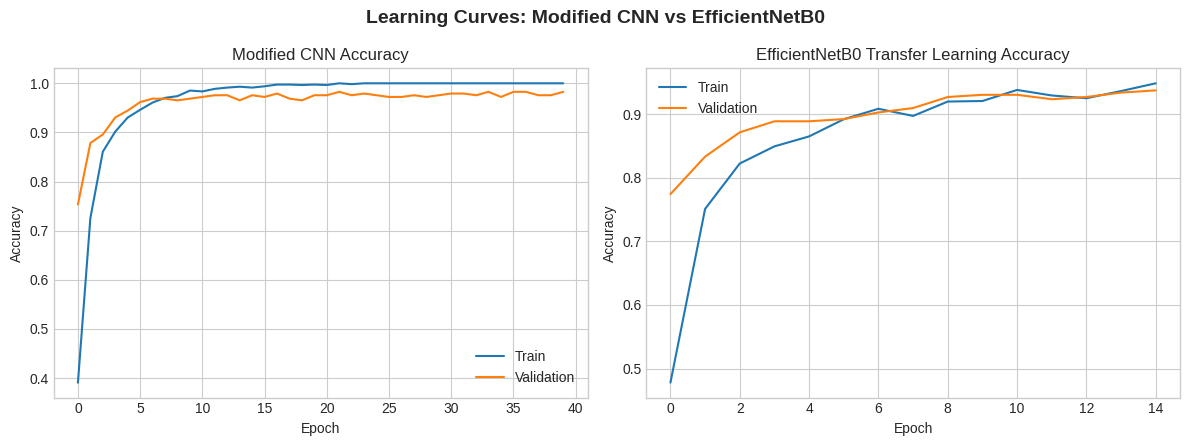

In [13]:
# Training vs Validation Accuracy: CNN vs EfficientNetB0

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(cnn_history.history["accuracy"], label="Train")
axes[0].plot(cnn_history.history["val_accuracy"], label="Validation")
axes[0].set_title("Modified CNN Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(transfer_history.history["accuracy"], label="Train")
axes[1].plot(transfer_history.history["val_accuracy"], label="Validation")
axes[1].set_title("EfficientNetB0 Transfer Learning Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.suptitle("Learning Curves: Modified CNN vs EfficientNetB0", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


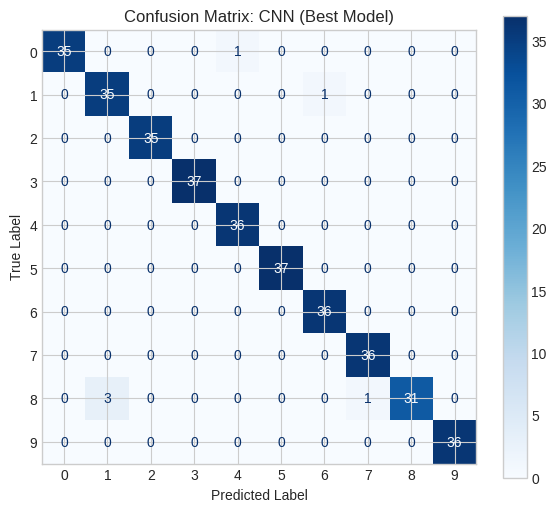

In [14]:
# Confusion Matrix for the Stronger Model

if transfer_accuracy >= cnn_accuracy:
    best_name, best_pred = "Transfer Learning", transfer_test_pred
else:
    best_name, best_pred = "CNN", cnn_test_pred

cm = confusion_matrix(y_test, best_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[str(i) for i in range(10)])

fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(cmap="Blues", ax=ax, colorbar=True, values_format="d")

plt.title(f"Confusion Matrix: {best_name} (Best Model)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Best Model           : CNN
Correctly classified : 354 / 360
Misclassified        : 6 / 360


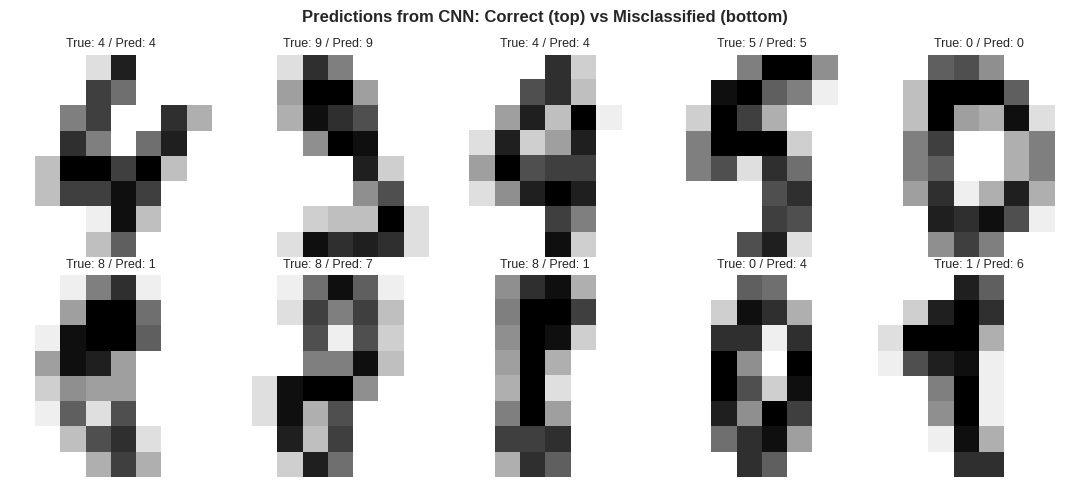

In [15]:
# Visualize Correct and Misclassified Predictions from the Best Model

misclassified = np.where(best_pred != y_test)[0]
correct = np.where(best_pred == y_test)[0]

print(f"Best Model           : {best_name}")
print(f"Correctly classified : {len(correct)} / {len(y_test)}")
print(f"Misclassified        : {len(misclassified)} / {len(y_test)}")

n_correct = min(5, len(correct))
n_wrong = min(5, len(misclassified))
sample_correct = np.random.choice(correct, size=n_correct, replace=False) if n_correct else []
sample_wrong = misclassified[:n_wrong]

fig, axes = plt.subplots(2, 5, figsize=(11, 5))

for ax in axes[0]:
    ax.axis("off")
for ax in axes[1]:
    ax.axis("off")

for ax, idx in zip(axes[0], sample_correct):
    ax.imshow(X_test[idx], cmap="gray_r")
    ax.set_title(f"True: {y_test[idx]} / Pred: {best_pred[idx]}", fontsize=9)
    ax.axis("off")

for ax, idx in zip(axes[1], sample_wrong):
    ax.imshow(X_test[idx], cmap="gray_r")
    ax.set_title(f"True: {y_test[idx]} / Pred: {best_pred[idx]}", fontsize=9)
    ax.axis("off")

plt.suptitle(f"Predictions from {best_name}: Correct (top) vs Misclassified (bottom)",
             fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


## **Expected Output**

After running all cells, the notebook should display:

- Dataset shape, class counts, and sample digit images.
- Training, validation, and test split shapes.
- The modified CNN summary showing 16, 32, and 64 convolution filters, Tanh activations, Dropout, and a Softmax output.
- CNN training history, test accuracy, and classification report.
- The EfficientNetB0 transfer-learning model summary with its frozen base and Tanh/Dropout classifier head.
- Transfer-learning test accuracy and classification report.
- A comparison table and side-by-side learning curves.
- A confusion matrix and examples of correct and incorrect predictions.

The exact accuracy values and number of epochs are determined by the actual training run; they should be reported from the notebook output rather than guessed in advance.


## **Performance Evaluation**

The models are evaluated on the same held-out test set. Test accuracy gives the proportion of correctly classified images, while the classification report provides precision, recall, and F1-score for each digit class. Learning curves help identify overfitting when training accuracy improves but validation accuracy stalls or decreases. The confusion matrix shows which digit classes are most often confused. No model is guaranteed to perform best before the experiment is run; compare the measured outputs to decide which approach suits this dataset.


## **Discussion**

The custom CNN was modified by changing the convolution filter counts to 16, 32, and 64, using a 5×5 kernel in the first convolution layer and 3×3 kernels in later layers, using Tanh instead of ReLU, and adding Dropout. RMSprop and early stopping are used for training. The transfer-learning approach uses a frozen EfficientNetB0 pretrained on ImageNet, with a 128-unit Tanh dense layer, Dropout, and a Softmax output. These changes create a meaningful architectural comparison, but they do not guarantee that one model will be more accurate. The final conclusion should be based on the actual test accuracy, classification report, and learning curves after running all cells.


## **Viva Questions**

1. **Q:** What is a convolution kernel?  
   **A:** A small matrix that slides over an image to detect local patterns such as edges and curves.

2. **Q:** What is the purpose of changing the number of filters?  
   **A:** More filters allow a layer to learn more types of visual features, but they also increase computation.

3. **Q:** Which kernel sizes are used in the modified CNN?  
   **A:** A 5×5 kernel in the first convolution layer and 3×3 kernels in the later convolution layers.

4. **Q:** Which activation functions are used?  
   **A:** Tanh is used in the custom CNN hidden layers and the transfer-learning dense layer; Softmax is used in both output layers.

5. **Q:** Why is Softmax used in the output layer?  
   **A:** This is a ten-class classification problem, and Softmax converts the output scores into class probabilities.

6. **Q:** What is Dropout?  
   **A:** A regularization technique that randomly disables some units during training to help reduce overfitting.

7. **Q:** What is transfer learning?  
   **A:** Reusing a model pretrained on a large dataset and adapting its features to a new task.

8. **Q:** Why is the EfficientNetB0 base frozen?  
   **A:** To keep its pretrained weights fixed while training the new classifier head, reducing training cost.

9. **Q:** Why are the images resized to 128×128 RGB for EfficientNetB0?  
   **A:** The pretrained model expects three-channel images of a suitable spatial size; the original Digits images are only 8×8 grayscale.

10. **Q:** Does transfer learning always give higher accuracy?  
    **A:** No. Its performance depends on the relationship between the pretrained data and the target dataset, so the test results must be compared.


## **Exercises**

1. Change the Dropout rate from 0.35 to 0.20 or 0.50 and compare validation performance.
2. Try 32, 64, and 128 filters in the custom CNN and compare training time and test accuracy.
3. Replace Tanh with ReLU or LeakyReLU and observe the effect on the learning curves.
4. Unfreeze only the top few EfficientNetB0 layers and fine-tune with a very small learning rate (for example, 1e-5).
5. Compare the test accuracy, precision, recall, F1-score, and confusion matrix for both approaches.

## **Lab Report Submission Checklist**

- Include the model summaries showing the changed architecture.
- Include the actual accuracy and classification reports from the run.
- Include the learning curves and confusion matrix.
- Explain the effect of kernel size, filter count, activation functions, and Dropout.
- State which model performed better based on the measured test results, not a pre-assumed result.
